In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import spacy
from collections import Counter

# Load dataset
df = pd.read_csv("fakenews.csv")

# Load spaCy English model
nlp = spacy.load("en_core_web_sm")

In [2]:
# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Function to extract entities
def extract_entities(text):
    doc = nlp(text)

    entities = []

    for ent in doc.ents:
        if ent.label_ in ["PERSON", "ORG", "GPE", "LOC"]:
            if ent.label_ == "PERSON":
                category = "People"
            elif ent.label_ == "ORG":
                category = "Organizations"
            else:
                category = "Locations"

            entities.append({
                "entity": ent.text,
                "entity_type": category
            })

    return entities

In [3]:
# Extract entities from every article
records = []

for _, row in df.iterrows():
    for entity in extract_entities(row["text"]):
        records.append({
            "news_id": row["news_id"],
            "label": row["label"],
            "entity": entity["entity"],
            "entity_type": entity["entity_type"]
        })

# Create entity DataFrame
entities_df = pd.DataFrame(
    records,
    columns=["news_id", "label", "entity", "entity_type"]
)


Entity Type Frequency by Label:
label          Fake  Real
entity_type              
Locations       404   428
Organizations   138   118
People          128    98

Average Entity Occurrences per Article:
label           Fake   Real
entity_type                
Locations      0.364  0.388
Organizations  0.124  0.107
People         0.115  0.089

Top 10 Entities in Real News:
entity
Bangladesh              239
Chittagong              120
Breakthrough             98
Dhaka                    55
Uncertainty              18
the moon Uncertainty     14
Local                    14
Dhaka Local              13
the moon Doctors         13
Dhaka Doctors            12
Name: count, dtype: int64

Top 10 Entities in Fake News:
entity
Bangladesh              239
Breakthrough            128
Chittagong              111
Dhaka                    39
Uncertainty              19
the moon Government      18
Dhaka Uncertainty        16
the moon Uncertainty     15
the moon Doctors         14
Dhaka Incidents       

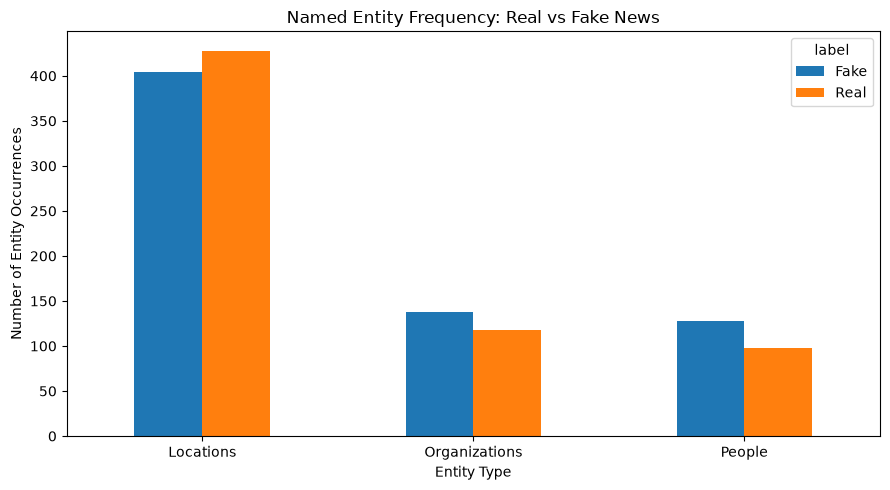

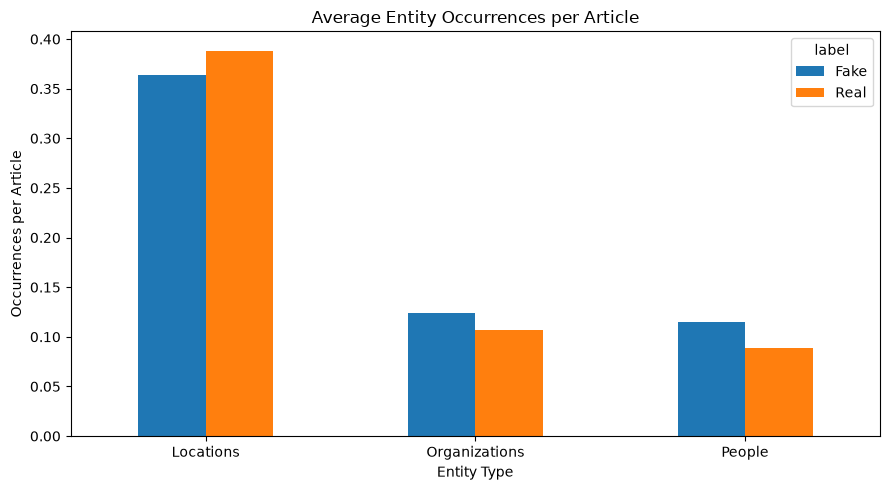


Results saved successfully.

Named entity frequency analysis completed.


In [4]:

if entities_df.empty:
    print("No named entities found in the dataset.")

else:
    # Entity frequency by news label
    print("\nEntity Type Frequency by Label:")
    frequency = pd.crosstab(
        entities_df["entity_type"],
        entities_df["label"]
    )
    print(frequency)

    # Normalize frequency by number of articles in each class
    article_counts = df["label"].value_counts()

    normalized = frequency.copy().astype(float)

    for label in normalized.columns:
        if article_counts.get(label, 0) > 0:
            normalized[label] = (
                normalized[label] / article_counts[label]
            )

    print("\nAverage Entity Occurrences per Article:")
    print(normalized.round(3))

    # Most frequent entities in each class
    for label in df["label"].dropna().unique():
        print(f"\nTop 10 Entities in {label} News:")

        label_data = entities_df[
            entities_df["label"] == label
        ]

        print(
            label_data["entity"]
            .value_counts()
            .head(10)
        )

    # Compare entity category frequency
    frequency.plot(
        kind="bar",
        figsize=(9, 5)
    )

    plt.title("Named Entity Frequency: Real vs Fake News")
    plt.xlabel("Entity Type")
    plt.ylabel("Number of Entity Occurrences")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Compare normalized frequencies
    normalized.plot(
        kind="bar",
        figsize=(9, 5)
    )

    plt.title("Average Entity Occurrences per Article")
    plt.xlabel("Entity Type")
    plt.ylabel("Occurrences per Article")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Save entity frequency results
    frequency.to_csv("entity_frequency_by_label.csv")
    normalized.to_csv("normalized_entity_frequency.csv")
    entities_df.to_csv("entity_frequency_details.csv", index=False)

    print("\nResults saved successfully.")

print("\nNamed entity frequency analysis completed.")